# 01 - Auditoria estrutural do bruto

Primeira etapa do pipeline (`acquire -> eda -> prepare -> explore -> train`). Este notebook
faz **auditoria estrutural** do dataset bruto *Default of Credit Card Clients* (UCI 350):
shape, nulos, duplicatas, domínios de códigos e distribuições marginais.

**Escopo deliberado:** nenhuma relação entre feature e alvo é calculada aqui. Versões
anteriores deste EDA correlacionavam as 19 features financeiras com o alvo nas 30.000 linhas
do bruto — incluindo as linhas que depois viram o conjunto de teste. Essa exposição está
declarada em [`docs/evidence/fase-1.md`](../docs/evidence/fase-1.md) e o artefato histórico
contaminante foi preservado em `reports/eda/history/`. A exploração supervisionada passou a
viver exclusivamente no split de treino, no notebook
[`02_explore_train.ipynb`](02_explore_train.ipynb) e no estágio DVC `explore`.

A lógica vive em `src/credit_monitoring/eda.py`; o mesmo código roda no estágio `eda` do
`dvc.yaml`. Aqui as saídas vão para uma pasta temporária para não alterar as saídas
rastreadas pelo DVC.

In [1]:
import json
import tempfile
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

from credit_monitoring.config import load_config
from credit_monitoring.data.loading import default_raw_path, load_raw
from credit_monitoring.eda import run_eda

pd.options.display.float_format = "{:,.3f}".format

config = load_config()
raw_csv = default_raw_path(config)
raw = load_raw(raw_csv, config)
target = config["dataset"]["canonical_target"]

output_dir = Path(tempfile.mkdtemp(prefix="eda_"))
summary = run_eda(
    raw_csv,
    config,
    figures_dir=output_dir / "figures",
    summary_path=output_dir / "eda_summary.json",
)


def show(name):
    display(Image(filename=output_dir / "figures" / name))

## 1. Visão geral e qualidade

O CSV tem uma linha inicial `X1..X23;Y` descartada na leitura (`header=1`); a coluna alvo é
renomeada para `default_payment_next_month`.

In [2]:
quality = {
    key: summary[key]
    for key in [
        "rows",
        "columns",
        "null_values",
        "duplicated_rows",
        "duplicated_ids",
        "non_numeric_columns",
        "age_min",
        "age_max",
        "limit_bal_min",
        "limit_bal_max",
        "limit_bal_non_positive",
        "negative_bill_amt_values",
        "negative_pay_amt_values",
    ]
}
display(pd.Series(quality, name="valor").to_frame())
display(raw.head())
display(raw.describe().T)

,valor
rows,30000
columns,25
null_values,0
duplicated_rows,0
duplicated_ids,0
non_numeric_columns,[]
age_min,21
age_max,79
limit_bal_min,10000
limit_bal_max,1000000


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default_payment_next_month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


,count,mean,std,min,25%,50%,75%,max
ID,"30,000.000","15,000.500","8,660.398",1.000,"7,500.750","15,000.500","22,500.250","30,000.000"
LIMIT_BAL,"30,000.000","167,484.323","129,747.662","10,000.000","50,000.000","140,000.000","240,000.000","1,000,000.000"
SEX,"30,000.000",1.604,0.489,1.000,1.000,2.000,2.000,2.000
EDUCATION,"30,000.000",1.853,0.790,0.000,1.000,2.000,2.000,6.000
MARRIAGE,"30,000.000",1.552,0.522,0.000,1.000,2.000,2.000,3.000
AGE,"30,000.000",35.486,9.218,21.000,28.000,34.000,41.000,79.000
PAY_0,"30,000.000",-0.017,1.124,-2.000,-1.000,0.000,0.000,8.000
PAY_2,"30,000.000",-0.134,1.197,-2.000,-1.000,0.000,0.000,8.000
PAY_3,"30,000.000",-0.166,1.197,-2.000,-1.000,0.000,0.000,8.000
PAY_4,"30,000.000",-0.221,1.169,-2.000,-1.000,0.000,0.000,8.000


## 2. Variável alvo (marginal)

A taxa global de default é uma propriedade **marginal** do bruto. Ela é inerente ao split
estratificado 70/15/15 exigido pelo plano — a estratificação usa o vetor de alvo completo
para definir as proporções de classe — e não carrega nenhuma relação feature-alvo.

,clientes,proporcao
default_payment_next_month,,
0,23364,0.779
1,6636,0.221


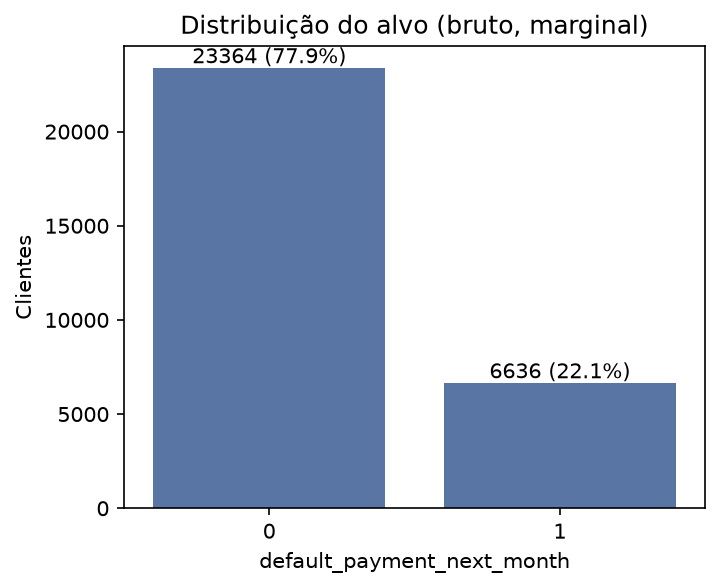

In [3]:
counts = raw[target].value_counts()
display(counts.rename("clientes").to_frame().assign(proporcao=counts / counts.sum()))
show("01_target_distribution.png")

## 3. Códigos categóricos

Códigos fora da documentação (`EDUCATION` 0/5/6, `MARRIAGE` 0) são apenas reportados, não
recodificados. A distribuição de `AGE` é marginal.

{
  "SEX": {},
  "EDUCATION": {
    "0": 14,
    "5": 280,
    "6": 51
  },
  "MARRIAGE": {
    "0": 54
  },
  "PAY": {
    "-2": 24415,
    "0": 95919
  }
}


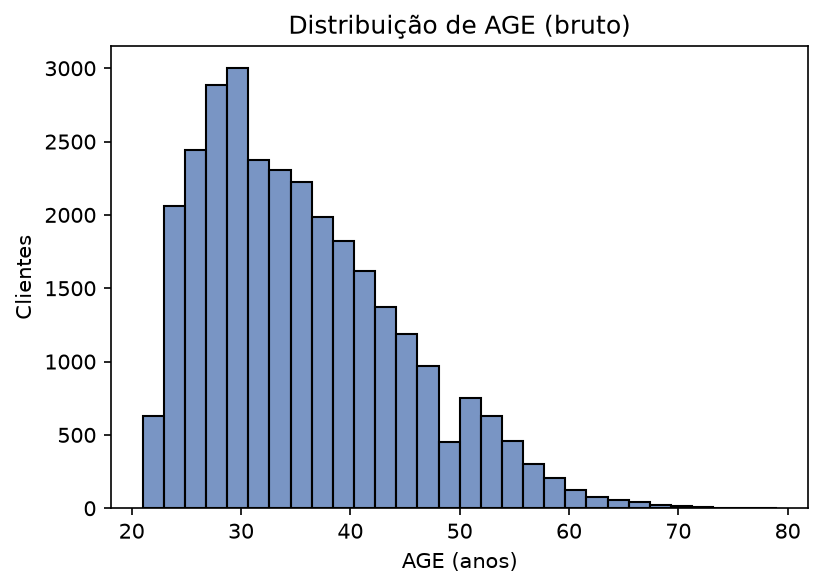

In [4]:
print(json.dumps(summary["undocumented_codes"], indent=2))
show("02_age_distribution.png")

## 4. Histórico de pagamento (`PAY_*`)

A documentação prevê -1 (pago em dia) e 1 a 9 (meses de atraso), mas os dados trazem também
-2 e 0. As contas são marginais; a relação com o alvo é tratada no notebook de treino.

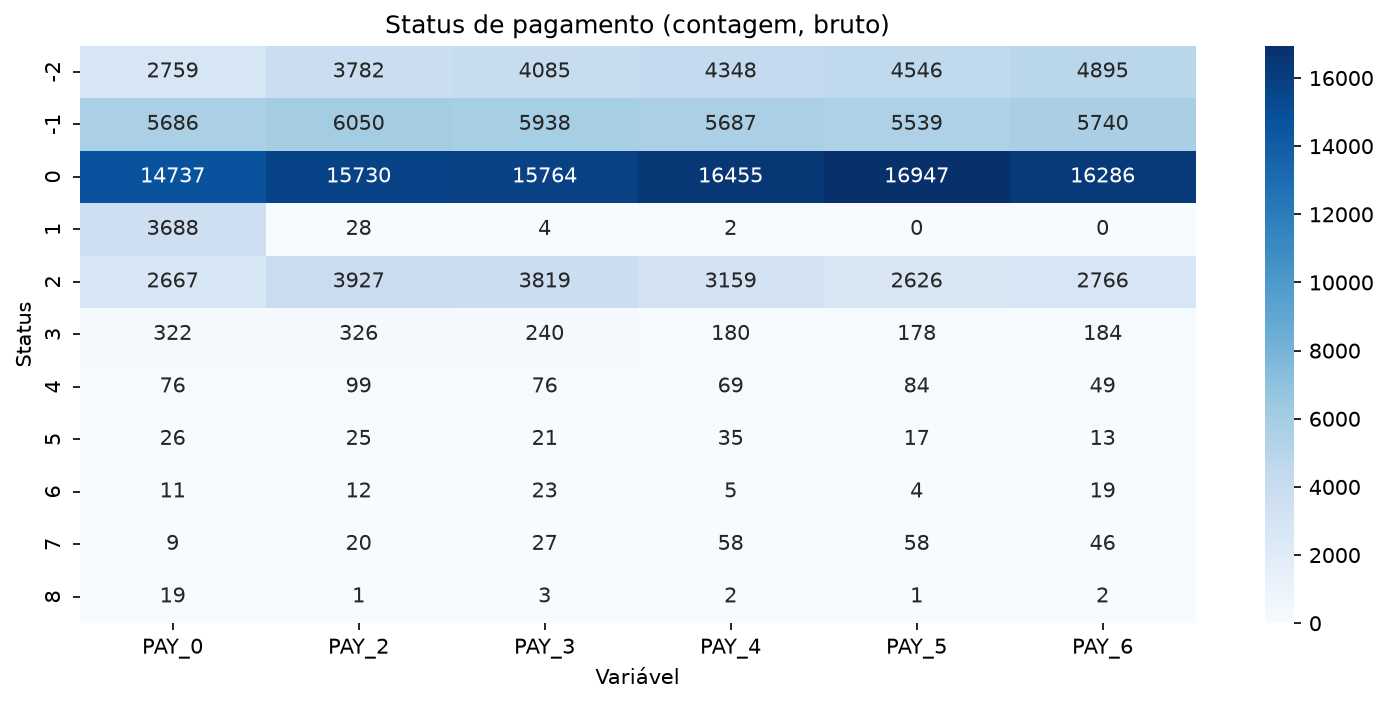

In [5]:
show("06_payment_status_counts.png")

## 5. Valores monetários

`LIMIT_BAL`, `BILL_AMT1..6` e `PAY_AMT1..6` têm cauda longa; `BILL_AMT*` contém valores
negativos (crédito na fatura).

BILL_AMT negativos: 3932
PAY_AMT negativos: 0


,outliers (IQR)
LIMIT_BAL,167
BILL_AMT1,2400
BILL_AMT2,2395
BILL_AMT3,2469
BILL_AMT4,2622
BILL_AMT5,2725
BILL_AMT6,2693
PAY_AMT1,2745
PAY_AMT2,2714
PAY_AMT3,2598


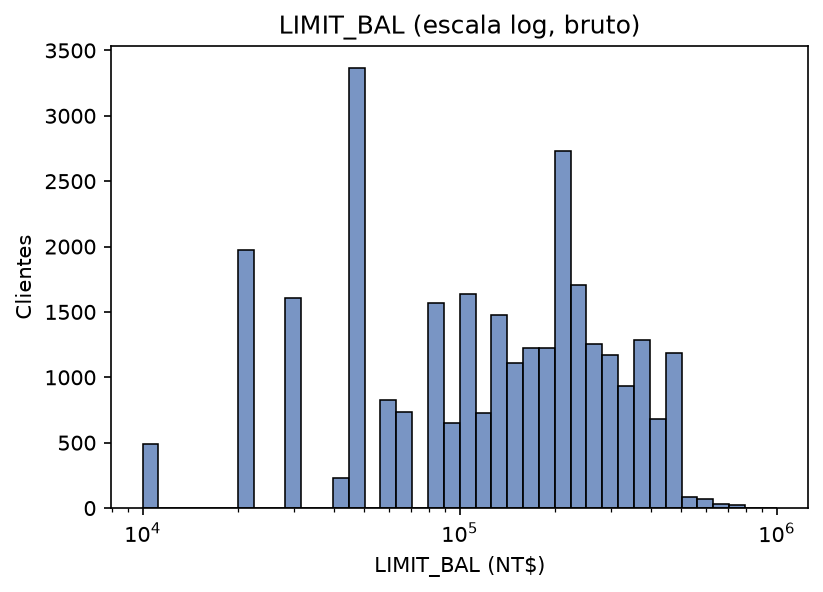

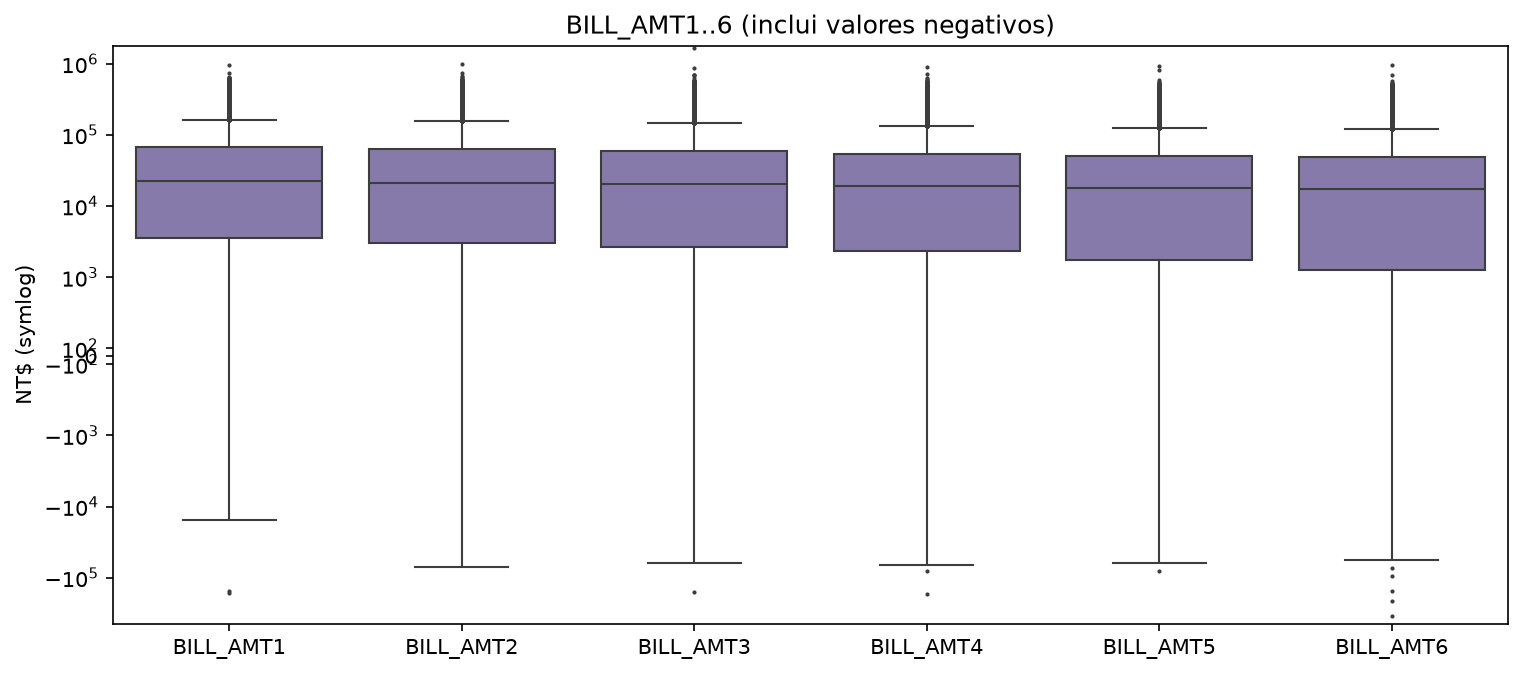

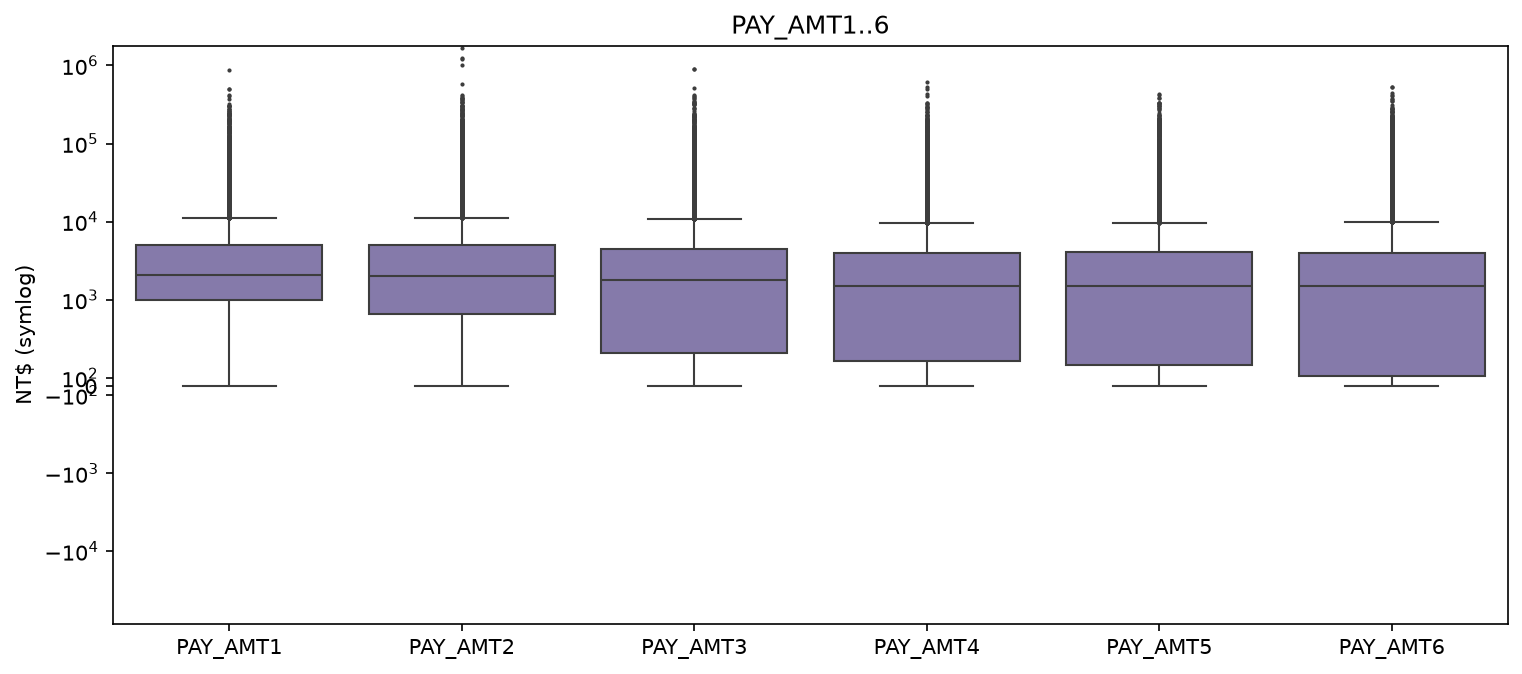

In [6]:
print("BILL_AMT negativos:", summary["negative_bill_amt_values"])
print("PAY_AMT negativos:", summary["negative_pay_amt_values"])
display(pd.Series(summary["iqr_outliers"], name="outliers (IQR)").to_frame())
show("03_limit_bal_distribution.png")
show("04_bill_amt_distribution.png")
show("05_pay_amt_distribution.png")

## 6. Próxima etapa

A exploração que orienta modelagem (correlações com o alvo, taxa de default por grupo
demográfico) fica em [`02_explore_train.ipynb`](02_explore_train.ipynb), sobre
`data/processed/train.csv` apenas.